# The Part-Time Penalty — Notebook 03: Validation & Final Findings
**Question:** Does the difference in *advertised* benefits between full-time and part-time postings remain within comparable occupation and wage groups?

**Purpose:** Audit Notebook 02 occupation labels, replace ambiguous classifications with conservative rules, and calculate defensible comparisons and sensitivity checks. This notebook **does not claim causal effects or actual benefit eligibility**.

**Input:** `Cleaned Data/indeed_cleaned_part_time_penalty.csv.gz` from Notebook 01. Notebook 02 is not required to run, but we compare its saved weighted result if present.

**Run:** Google Colab → Runtime → Run all. Read the validation tables before presenting the findings.

## 1 — Mount Google Drive and load cleaned postings

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/content/drive/MyDrive/The Part-Time Penalty')
DATA = ROOT / 'Cleaned Data'
OUT = DATA / 'Notebook 03'
FIGS = ROOT / 'Visualizations' / 'Notebook 03'
OUT.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)
SOURCE = DATA / 'indeed_cleaned_part_time_penalty.csv.gz'
assert SOURCE.exists(), f'Missing {SOURCE}. Run Notebook 01 export.'
df = pd.read_csv(SOURCE, low_memory=False)
print(f'Loaded {len(df):,} rows from Notebook 01')
print('Columns:', df.columns.tolist())

Mounted at /content/drive
Loaded 140,816 rows from Notebook 01
Columns: ['jobid', 'job_title', 'job_type', 'salary_formatted', 'benefits', 'location', 'company_name', 'date_posted_parsed', 'employment_type', 'hourly_min', 'hourly_max', 'hourly_midpoint', 'salary_parse_status', 'benefits_disclosed', 'health_insurance', 'paid_time_off', 'retirement', 'dental_insurance', 'flexible_schedule']


## 2 — Validate data types, duplicates, salary and benefit indicators
We do **not** silently convert unknown benefit flags to false. Missing indicators are counted and excluded from rate denominators. The original notebook generally supplies true/false flags.

In [2]:
BENEFITS = ['health_insurance','paid_time_off','retirement','dental_insurance','flexible_schedule']
needed = ['jobid','job_title','employment_type','hourly_midpoint','salary_formatted','benefits_disclosed'] + BENEFITS
assert not (set(needed) - set(df.columns)), f'Missing columns: {set(needed)-set(df.columns)}'
print('Duplicate job IDs:', df['jobid'].duplicated().sum())
# Keep first job ID if duplicate; show count rather than silently dropping.
df = df.drop_duplicates(subset='jobid', keep='first').copy()
for c in BENEFITS + ['benefits_disclosed']:
    mapped = df[c].astype('string').str.strip().str.lower().map({'true':True,'false':False,'1':True,'0':False})
    print(f'{c}: missing/unrecognized flags = {mapped.isna().sum():,}')
    df[c] = mapped.astype('boolean')
df['hourly_midpoint'] = pd.to_numeric(df['hourly_midpoint'], errors='coerce')
valid = df['employment_type'].isin(['Full-time','Part-time']) & df['hourly_midpoint'].between(5,500)
a = df.loc[valid].copy()
a['job_title'] = a['job_title'].fillna('').astype(str)
print('\nAnalysis population:', f'{len(a):,}')
display(a['employment_type'].value_counts().to_frame('postings'))
display(a[BENEFITS+['benefits_disclosed']].isna().sum().to_frame('missing_flags'))
assert len(a)>0, 'No valid FT/PT + wage observations.'

Duplicate job IDs: 0
health_insurance: missing/unrecognized flags = 0
paid_time_off: missing/unrecognized flags = 0
retirement: missing/unrecognized flags = 0
dental_insurance: missing/unrecognized flags = 0
flexible_schedule: missing/unrecognized flags = 0
benefits_disclosed: missing/unrecognized flags = 0

Analysis population: 81,398


,postings
employment_type,
Full-time,66311
Part-time,15087


,missing_flags
health_insurance,0
paid_time_off,0
retirement,0
dental_insurance,0
flexible_schedule,0
benefits_disclosed,0


## 3 — Improve occupation classification, conservatively

The Notebook 02 classifier assigned nearly 60% to Other. Here we add common job families, fix ambiguous titles by **prioritizing specific occupations**, and explicitly mark titles that match multiple families as `Ambiguous / Multiple`. Do not interpret these labels as official occupational codes.

**Important:** More classifications are not automatically better. The manual audit in Step 4 is mandatory.

In [3]:
# Patterns are intentionally transparent, editable, and ordered only for display.
# All patterns are checked; multi-matches are marked ambiguous rather than forced into a group.
PATTERNS = {
 'Healthcare & Care': r'\b(?:registered nurse|licensed practical nurse|nurse|nursing|\brn\b|\blvn\b|\blpn\b|\bcna\b|medical assistant|patient care|caregiver|home health|physical therap|occupational therap|pharmacist|pharmacy technician|dental assistant|dental hygienist|physician|clinical assistant|behavior technician|medical receptionist|veterinar|vet tech)\b',
 'Education & Childcare': r'\b(?:teacher|tutor|instructor|educator|teaching assistant|paraprofessional|substitute|childcare|child care|daycare|preschool|babysitter|nanny|camp counselor|school aide|teacher aide)\b',
 'Retail & Sales': r'\b(?:retail|cashier|sales associate|sales representative|salesperson|merchandis|stock associate|store manager|store clerk|brand ambassador|sales consultant|sales advisor|sales specialist)\b',
 'Food & Hospitality': r'\b(?:restaurant|server|waiter|waitress|bartender|barista|cook|chef|dishwasher|food service|food prep|kitchen|hostess|hotel|housekeeping|banquet|catering|bakery|baker|busser|line cook|prep cook|food runner|room attendant)\b',
 'Logistics & Transportation': r'\b(?:warehouse|delivery driver|truck driver|driver|courier|forklift|package handler|shipping|receiving|material handler|logistics|dispatcher|distribution center|delivery associate|order picker|inventory clerk)\b',
 'Office & Administration': r'\b(?:administrative|admin assistant|office assistant|office manager|receptionist|data entry|executive assistant|secretary|bookkeeper|payroll|accounting clerk|customer service|call center|scheduler|records clerk|clerical|office coordinator|front desk receptionist)\b',
 'Technology & Engineering': r'\b(?:software|developer|programmer|data analyst|data scientist|engineer|it support|help desk|cybersecurity|network technician|web designer|qa analyst|systems analyst|computer technician|technical support specialist)\b',
 'Facilities & Security': r'\b(?:janitor|custodian|cleaner|maintenance|landscap|groundskeeper|security guard|security officer|electrician|plumber|hvac|mechanic|facilities|building technician|maintenance technician)\b',
 'Personal Services': r'\b(?:hairstylist|hair stylist|barber|esthetician|cosmetolog|nail technician|massage therapist|personal trainer|fitness instructor|fitness coach|dog groomer|pet sitter|salon|spa attendant)\b',
 'Social & Community Services': r'\b(?:social worker|case manager|caseworker|social services|community outreach|peer support|youth counselor|mental health counselor|housing navigator|program assistant|community organizer)\b',
 'Finance & Business': r'\b(?:accountant|financial analyst|financial advisor|loan officer|bank teller|tax preparer|underwriter|business analyst|insurance agent|claims adjuster)\b',
}
compiled={k:re.compile(v,re.I) for k,v in PATTERNS.items()}
def classify(title):
    matches=[k for k,p in compiled.items() if p.search(title)]
    if not matches: return 'Other / Unclassified'
    if len(matches)>1: return 'Ambiguous / Multiple'
    return matches[0]
a['occupation_v3'] = a['job_title'].map(classify)
counts=pd.crosstab(a['occupation_v3'],a['employment_type']).reindex(columns=['Full-time','Part-time'],fill_value=0)
counts['Total']=counts.sum(axis=1)
display(counts.sort_values('Total',ascending=False))
print('Unclassified:',f"{a.occupation_v3.eq('Other / Unclassified').mean():.1%}")
print('Ambiguous:',f"{a.occupation_v3.eq('Ambiguous / Multiple').mean():.1%}")
counts.to_csv(OUT/'03_occupation_counts.csv')

employment_type,Full-time,Part-time,Total
occupation_v3,,,
Other / Unclassified,39776,7721,47497
Technology & Engineering,10745,52,10797
Healthcare & Care,3271,1156,4427
Retail & Sales,1972,2076,4048
Food & Hospitality,1935,1611,3546
Office & Administration,2393,578,2971
Facilities & Security,2036,286,2322
Logistics & Transportation,1690,282,1972
Education & Childcare,513,937,1450


Unclassified: 58.4%
Ambiguous: 1.0%


## 4 — Mandatory classification audit

Review **at least 5 titles per occupation and employment type** where possible, plus common unclassified and ambiguous titles. The CSV includes `reviewer_label` and `notes` columns for your team to fill in. A model cannot verify these heuristic labels for you. **Do not report occupation findings as final until this audit is complete.**

In [4]:
samples=[]
for (occ,typ),g in a.groupby(['occupation_v3','employment_type'],dropna=False):
    # Include frequent and randomly selected titles to catch systematic and rare errors
    top=g['job_title'].value_counts().head(5).index.tolist()
    random_titles=g['job_title'].drop_duplicates().sample(min(5,g['job_title'].nunique()),random_state=42).tolist()
    for t in dict.fromkeys(top+random_titles):
        samples.append({'occupation_v3':occ,'employment_type':typ,'job_title':t,
                        'reviewer_label':'','notes':''})
audit=pd.DataFrame(samples)
display(audit.head(35))
audit.to_csv(OUT/'03_manual_classification_audit_FILL_THIS_IN.csv',index=False)
print('Saved',len(audit),'title examples for manual review.')
print('\nTop unclassified titles:')
display(a.loc[a.occupation_v3.eq('Other / Unclassified'),'job_title'].value_counts().head(25).to_frame('postings'))
print('\nTop ambiguous titles:')
display(a.loc[a.occupation_v3.eq('Ambiguous / Multiple'),'job_title'].value_counts().head(20).to_frame('postings'))

,occupation_v3,employment_type,job_title,reviewer_label,notes
0,Ambiguous / Multiple,Full-time,Medical Receptionist,,
1,Ambiguous / Multiple,Full-time,RN Case Manager,,
2,Ambiguous / Multiple,Full-time,Senior Complex Case Manager (RN) - D-SNP (Temp...,,
3,Ambiguous / Multiple,Full-time,Physical Therapist Case Manager: Home Health,,
4,Ambiguous / Multiple,Full-time,Cardiopulmonary Patient Educator - Registered ...,,
5,Ambiguous / Multiple,Full-time,"Staff Systems Test Engineer, Scenario Quality ...",,
6,Ambiguous / Multiple,Full-time,"System Development Engineer, AI/ML (Accelerato...",,
7,Ambiguous / Multiple,Full-time,Staff Backend Server Engineer,,
8,Ambiguous / Multiple,Full-time,Home Health RN Case Manager,,
9,Ambiguous / Multiple,Full-time,Consumer Insurance — Call Center Phone Sales R...,,


Saved 254 title examples for manual review.

Top unclassified titles:


,postings
job_title,
Service Team,315
Team Member,269
Stocker,166
Project Manager,144
Housekeeper,140
Physical Therapist,123
General Manager,117
Host,116
Personal Shopper (In-Store),101



Top ambiguous titles:


,postings
job_title,
Medical Receptionist,31
RN Case Manager,15
Senior Complex Case Manager (RN) - D-SNP (Temporary),11
Cashier/Food Service Worker,10
Physical Therapist Case Manager: Home Health,9
Cardiopulmonary Patient Educator - Registered Nurse,7
Maintenance Engineer,6
Cashier - Customer Service Rep,6
CASHIER/FOOD SERVICE WORKER (PART TIME),5


## 5 — Define comparable groups and calculate gaps

A comparable cell is the **same occupation × same hourly wage band**, with at least **30 full-time and 30 part-time postings**. Exclude unclassified and ambiguous jobs from the main adjusted comparison; retain them for transparency and a sensitivity check.

The summary uses `min(n_full_time, n_part_time)` as each cell's weight. This is a **descriptive standardized gap**, not a causal estimate. Rates use nonmissing benefit flags as denominators.

In [5]:
WAGE_BINS=[0,15,20,25,30,40,60,np.inf]
WAGE_LABELS=['<$15','$15–20','$20–25','$25–30','$30–40','$40–60','$60+']
a['wage_band']=pd.cut(a['hourly_midpoint'],WAGE_BINS,labels=WAGE_LABELS,right=False)
MIN_N=30

def matched_analysis(frame, label, min_n=MIN_N):
    grouped=(frame.groupby(['occupation_v3','wage_band','employment_type'],observed=True)
             .agg(n=('jobid','size'),**{x:(x,'mean') for x in BENEFITS}).reset_index())
    pivot=grouped.pivot(index=['occupation_v3','wage_band'],columns='employment_type',values=['n']+BENEFITS)
    pivot.columns=[f'{metric}_{typ.replace("-","_").lower()}' for metric,typ in pivot.columns]
    pivot=pivot.reset_index()
    for typ in ['full_time','part_time']:
        c=f'n_{typ}'
        if c not in pivot:pivot[c]=0
    pivot[['n_full_time','n_part_time']]=pivot[['n_full_time','n_part_time']].fillna(0).astype(int)
    matched=pivot.loc[(pivot.n_full_time>=min_n)&(pivot.n_part_time>=min_n)].copy()
    matched['weight']=matched[['n_full_time','n_part_time']].min(axis=1)
    rows=[]
    for benefit in BENEFITS:
        ft=f'{benefit}_full_time';pt=f'{benefit}_part_time'
        if ft not in matched or pt not in matched:continue
        matched[f'{benefit}_gap_pp']=100*(matched[ft]-matched[pt])
        sub=matched.dropna(subset=[f'{benefit}_gap_pp'])
        if len(sub):
            rows.append({'sample':label,'benefit':benefit,'weighted_gap_pp':np.average(sub[f'{benefit}_gap_pp'],weights=sub.weight),
                         'matched_cells':len(sub),'matched_weight':int(sub.weight.sum()),
                         'total_ft_in_cells':int(sub.n_full_time.sum()),'total_pt_in_cells':int(sub.n_part_time.sum())})
    return matched,pd.DataFrame(rows)

main=a.loc[~a.occupation_v3.isin(['Other / Unclassified','Ambiguous / Multiple'])].copy()
matched,summary=matched_analysis(main,'main')
print('Main population:',len(main),'| comparable cells:',len(matched))
display(summary.round(2))
assert len(matched)>0,'No comparable groups. Inspect occupation counts and MIN_N.'
matched.to_csv(OUT/'03_matched_cells_main.csv',index=False)
summary.to_csv(OUT/'03_weighted_gap_main.csv',index=False)

Main population: 33076 | comparable cells: 27


/tmp/ipykernel_474/2575306356.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pivot[['n_full_time','n_part_time']]=pivot[['n_full_time','n_part_time']].fillna(0).astype(int)


,sample,benefit,weighted_gap_pp,matched_cells,matched_weight,total_ft_in_cells,total_pt_in_cells
0,main,health_insurance,27.57,27,4399,10366,6502
1,main,paid_time_off,18.93,27,4399,10366,6502
2,main,retirement,19.20,27,4399,10366,6502
3,main,dental_insurance,23.12,27,4399,10366,6502
4,main,flexible_schedule,-7.65,27,4399,10366,6502


## 6 — Charts: headline benefits and strongest/weakest comparable cells

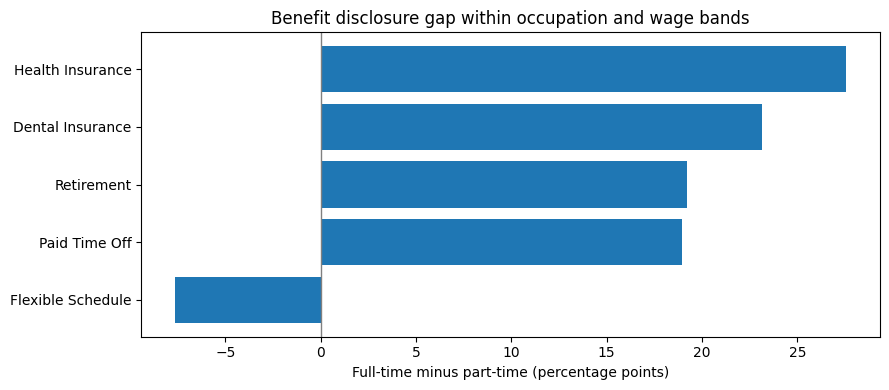

Largest health-insurance disclosure gaps (descriptive):


,occupation_v3,wage_band,n_full_time,n_part_time,health_insurance_gap_pp
60,Retail & Sales,$30–40,450,71,73.402191
3,Education & Childcare,$25–30,102,149,61.554152
2,Education & Childcare,$20–25,134,213,50.672693
44,Office & Administration,$20–25,724,129,47.488115
45,Office & Administration,$25–30,524,53,47.457871
4,Education & Childcare,$30–40,120,108,43.518519
37,Logistics & Transportation,$20–25,614,129,41.773351
24,Food & Hospitality,$25–30,430,94,39.713013
25,Food & Hospitality,$30–40,209,34,39.220377
9,Facilities & Security,$20–25,421,121,38.597593


Smallest / reversed gaps:


,occupation_v3,wage_band,n_full_time,n_part_time,health_insurance_gap_pp
8,Facilities & Security,$15–20,146,100,30.465753
58,Retail & Sales,$20–25,450,430,30.294574
23,Food & Hospitality,$20–25,834,497,30.182534
34,Healthcare & Care,$60+,1446,270,29.515906
57,Retail & Sales,$15–20,382,1510,27.87282
30,Healthcare & Care,$20–25,443,407,22.724777
32,Healthcare & Care,$30–40,340,98,22.623049
29,Healthcare & Care,$15–20,103,82,21.442103
36,Logistics & Transportation,$15–20,261,88,19.919018
31,Healthcare & Care,$25–30,386,155,6.540197


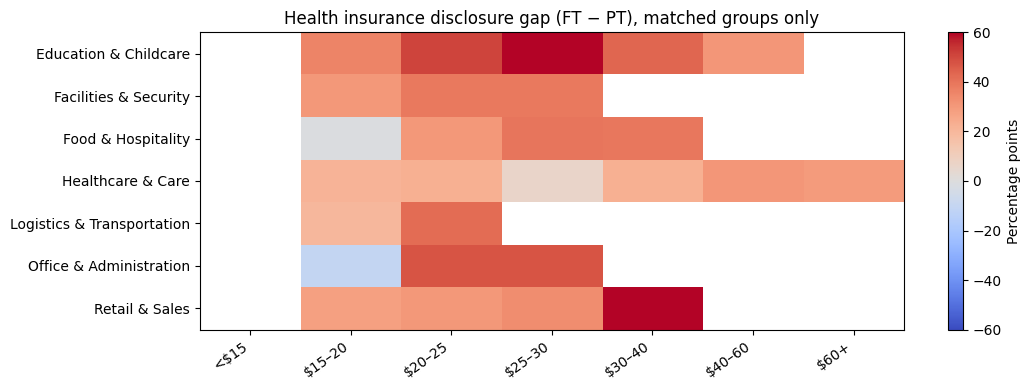

In [6]:
fig,ax=plt.subplots(figsize=(9,4))
s=summary.sort_values('weighted_gap_pp')
ax.barh(s['benefit'].str.replace('_',' ').str.title(),s['weighted_gap_pp'])
ax.axvline(0,color='gray',lw=1)
ax.set(xlabel='Full-time minus part-time (percentage points)',title='Benefit disclosure gap within occupation and wage bands')
plt.tight_layout();plt.savefig(FIGS/'03_main_weighted_gaps.png',dpi=180,bbox_inches='tight');plt.show()
view=matched[['occupation_v3','wage_band','n_full_time','n_part_time','health_insurance_gap_pp']].sort_values('health_insurance_gap_pp',ascending=False)
print('Largest health-insurance disclosure gaps (descriptive):')
display(view.head(12).round(2))
print('Smallest / reversed gaps:')
display(view.tail(12).round(2))
view.to_csv(OUT/'03_ranked_health_gaps.csv',index=False)
heat=matched.pivot(index='occupation_v3',columns='wage_band',values='health_insurance_gap_pp').reindex(columns=WAGE_LABELS)
fig,ax=plt.subplots(figsize=(11,max(4,len(heat)*.5)))
im=ax.imshow(heat.to_numpy(dtype=float),aspect='auto',cmap='coolwarm',vmin=-60,vmax=60)
ax.set_xticks(range(len(heat.columns)),heat.columns,rotation=35,ha='right')
ax.set_yticks(range(len(heat.index)),heat.index)
ax.set_title('Health insurance disclosure gap (FT − PT), matched groups only')
fig.colorbar(im,ax=ax,label='Percentage points')
plt.tight_layout();plt.savefig(FIGS/'03_health_gap_heatmap.png',dpi=180,bbox_inches='tight');plt.show()

## 7 — Robustness tests

Compare the main result against (a) **hourly-labeled salaries only**, (b) postings listing **at least one benefit**, (c) a stricter **50-per-type minimum**, and (d) including the unclassified category as a separate stratum. The same cell definitions apply within each subset; different samples may contain different comparable cells, so comparisons are descriptive, not identical-population estimates.

In [7]:
hourly_re=r'\b(?:hour|hourly|hora|horas)\b'
checks={
 'main':(main,30),
 'hourly_salaries_only':(main.loc[main.salary_formatted.fillna('').str.contains(hourly_re,case=False,regex=True)],30),
 'benefit_disclosers_only':(main.loc[main.benefits_disclosed.eq(True)],30),
 'stricter_min_50':(main,50),
 'include_unclassified':(a.loc[~a.occupation_v3.eq('Ambiguous / Multiple')],30)
}
all_summaries=[]
for name,(subset,min_n) in checks.items():
    m,s=matched_analysis(subset,name,min_n)
    print(name,'| postings:',len(subset),'| matched cells:',len(m))
    if len(s):all_summaries.append(s)
robust=pd.concat(all_summaries,ignore_index=True) if all_summaries else pd.DataFrame()
if len(robust):
    display(robust.pivot(index='benefit',columns='sample',values='weighted_gap_pp').round(2))
    robust.to_csv(OUT/'03_robustness_results.csv',index=False)
else:print('No sensitivity estimates passed the cell threshold.')

/tmp/ipykernel_474/2575306356.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pivot[['n_full_time','n_part_time']]=pivot[['n_full_time','n_part_time']].fillna(0).astype(int)
/tmp/ipykernel_474/2575306356.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pivot[['n_full_time','n_part_time']]=pivot[['n_full_time','n_part_time']].fillna(0).astype(int)
/tmp/ipykernel_474/2575306356.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) in

main | postings: 33076 | matched cells: 27
hourly_salaries_only | postings: 17979 | matched cells: 26
benefit_disclosers_only | postings: 22649 | matched cells: 23
stricter_min_50 | postings: 33076 | matched cells: 24
include_unclassified | postings: 80573 | matched cells: 34


sample,benefit_disclosers_only,hourly_salaries_only,include_unclassified,main,stricter_min_50
benefit,,,,,
dental_insurance,25.30,22.77,23.75,23.12,22.77
flexible_schedule,-15.01,-6.64,-8.72,-7.65,-7.41
health_insurance,31.33,27.44,26.61,27.57,27.32
paid_time_off,20.92,18.85,18.60,18.93,18.91
retirement,18.72,19.34,19.04,19.20,18.88


## 8 — Salary conversion check and employer concentration

Annual-to-hourly conversion assumes 2,080 hours/year, which may not describe part-time work. The hourly-only check above is important. Also check whether a few employers dominate particular matched cells.

In [8]:
print('Salary format examples for each employment type:')
for typ in ['Full-time','Part-time']:
    display(a.loc[a.employment_type.eq(typ),['salary_formatted','hourly_midpoint']].sample(min(12,(a.employment_type==typ).sum()),random_state=11))
if 'company_name' in main.columns:
    concentration=(main.groupby('company_name',dropna=False).size().sort_values(ascending=False).head(20).rename('postings'))
    display(concentration.to_frame())
    concentration.to_csv(OUT/'03_top_employers.csv')
    print('Top employer share:',round(concentration.iloc[0]/len(main)*100,2),'%')
print('Potentially implausible salary examples:')
display(a.sort_values('hourly_midpoint')[['job_title','employment_type','salary_formatted','hourly_midpoint']].head(12))
display(a.sort_values('hourly_midpoint',ascending=False)[['job_title','employment_type','salary_formatted','hourly_midpoint']].head(12))

Salary format examples for each employment type:


,salary_formatted,hourly_midpoint
134503,"$49,413 - $78,105 a year",30.653365
32854,"$75,379.50 - $85,280.00 a year",38.620072
129521,"$110,000 - $125,000 a year",56.490385
10071,"$307,500 - $451,000 a year",182.331731
108287,$26 - $28 an hour,27.000000
71322,$54.20 - $74.34 an hour,64.270000
65418,"$110,000 - $120,000 a year",55.288462
105445,"$404,000 - $519,000 a year",221.875000
121222,"$277,000 - $389,000 a year",160.096154
40633,"$33,000 - $35,000 a year",16.346154


,salary_formatted,hourly_midpoint
74082,$16.50 - $17.48 an hour,16.990
92396,$28 - $32 an hour,30.000
101056,$18 - $22 an hour,20.000
11338,$24 - $25 an hour,24.500
136370,$18.60 - $19.10 an hour,18.850
25558,$20 - $23 an hour,21.500
21331,$20.00 - $20.50 an hour,20.250
127887,$17.87 - $20.37 an hour,19.120
63880,$17.75 an hour,17.750
99698,$17.90 - $22.35 an hour,20.125


,postings
company_name,
Google,608
Panda Restaurant Group,533
NVIDIA,451
BJ's Restaurants,331
Tesla,319
Kaiser Permanente,202
Deloitte,191
Northrop Grumman,190
Dollar Tree,185


Top employer share: 1.84 %
Potentially implausible salary examples:


,job_title,employment_type,salary_formatted,hourly_midpoint
1585,Veterinary Extern - General Practice,Full-time,"$1,000 a month",5.769231
60021,"Part-Time Worship Leader (Gospel, Contemporary...",Part-time,"$1,000 a month",5.769231
40517,[Booth/Room Rental] Freelance Beauty Professional,Full-time,"$900 - $1,200 a month",6.057692
29888,Content Creator,Full-time,$250 a week,6.250000
74587,Electrical Line Mechanic Supervisor II,Full-time,"$10,600.97 - $15,419.09 por año",6.254822
38400,Lead Instructor: AI-Enabled Product Manager,Full-time,"$11,500 - $15,500 a year",6.490385
80575,Trash Valet,Part-time,$50 - $60 a day,6.875000
84200,"Senior Talent Business Partner, Early Career -...",Full-time,"$13,271 - $16,719 a year",7.209135
72848,Fractional Business Development Lead-San Franc...,Part-time,"$15,000 por año",7.211538
74472,Softball Coach,Part-time,"$1,000 - $1,500 a month",7.211538


,job_title,employment_type,salary_formatted,hourly_midpoint
136298,Locums Hematology and Oncology Physician in Sa...,Full-time,$450 - $500 an hour,475.000000
103430,"Neurosurgeon, Spine & Neurosurgery Associates ...",Full-time,"$900,000 - $985,000 a year",453.125000
33189,"Locums Gastroenterology Physician in Sonora, C...",Full-time,$425 - $450 an hour,437.500000
133341,Chief Engineer,Full-time,"$70,000 - $80,000 a month",432.692308
89931,Integration Specialist,Full-time,"$70,000 - $80,000 a month",432.692308
68107,Associate Designer - Young Contemporary Appare...,Full-time,"$650,000 - $950,000 a year",384.615385
34542,Manufacturing Engineer,Full-time,"$750,000 - $850,000 a year",384.615385
65551,"Physician, Cardiology -Interventional (Lodi, CA)",Full-time,"$795,493 a year",382.448558
53779,Locum Cardiologist,Part-time,"$3,000 a day",375.000000
119689,Obstetrics and Gynecology Physician (Full-time...,Full-time,"$3,000 por día",375.000000


## 9 — Export final analysis files for Tableau and presentation

This export preserves posting-level records, classifications, wages, and benefit indicators. **The manual audit CSV must be reviewed by a human before declaring occupation-specific findings final.**

In [9]:
cols=[c for c in ['jobid','company_name','job_title','location','employment_type','occupation_v3','wage_band','hourly_midpoint','salary_formatted','benefits_disclosed']+BENEFITS if c in a.columns]
a[cols].to_csv(OUT/'03_tableau_postings.csv.gz',index=False,compression='gzip')
print('Saved files in:',OUT)
for p in sorted(OUT.iterdir()):print(' -',p.name)
print('Charts in:',FIGS)
print('\nNOTE: The occupation audit requires manual review before reporting results as validated.')

Saved files in: /content/drive/MyDrive/The Part-Time Penalty/Cleaned Data/Notebook 03
 - 03_manual_classification_audit_FILL_THIS_IN.csv
 - 03_matched_cells_main.csv
 - 03_occupation_counts.csv
 - 03_ranked_health_gaps.csv
 - 03_robustness_results.csv
 - 03_tableau_postings.csv.gz
 - 03_top_employers.csv
 - 03_weighted_gap_main.csv
Charts in: /content/drive/MyDrive/The Part-Time Penalty/Visualizations/Notebook 03

NOTE: The occupation audit requires manual review before reporting results as validated.


## 10 — Write your three findings using the actual results

Fill these in **after inspecting the tables**, not before:

1. **Headline:** In comparable occupation × wage-band cells, the full-time minus part-time health insurance disclosure gap is **___ percentage points**, based on **___ matched cells** and **___ / ___** full-time / part-time postings in those cells.
2. **Tradeoff:** The flexible-schedule disclosure gap is **___ pp** (negative = part-time higher). This is an association in job advertisements, not proof of a tradeoff for individual workers.
3. **Where the gap is largest:** The largest adequately sampled cells are **___**, with **___** full-time and **___** part-time postings.

**Caveats to state in the presentation:** Unlisted ≠ unavailable; occupation labels are heuristic; advertised salaries are not guaranteed actual wages; annual salary conversion assumes 2,080 hours; comparisons are observational and cannot establish that part-time status causes the gap.

**Next:** Upload the executed `.ipynb` here **and** (once completed) your filled-in manual audit CSV. We will review the actual outputs before building Tableau.